In [10]:
""""Implement K-Nearest Neighbors algorithm on diabetes.csv dataset. Compute confusion
matrix, accuracy, error rate, precision and recall on the given dataset.
Dataset link : https://www.kaggle.com/datasets/abdallamahgoub/diabetes"""

'"Implement K-Nearest Neighbors algorithm on diabetes.csv dataset. Compute confusion\nmatrix, accuracy, error rate, precision and recall on the given dataset.\nDataset link : https://www.kaggle.com/datasets/abdallamahgoub/diabetes'

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

In [12]:
data = pd.read_csv("diabetes.csv")

print(data.head())

print("\nDataset Shape:", data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Shape: (768, 9)

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [13]:
columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns:

    data[col] = data[col].replace(0, np.nan)

    data[col] = data[col].fillna(data[col].median())

print(data.head())

print("\nMissing Values:")
print(data.isnull().sum())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [14]:
X = data.drop("Outcome", axis=1)

y = data["Outcome"]

print("Features:", X.shape)

print("Target:", y.shape)

Features: (768, 8)
Target: (768,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [16]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [17]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

prediction = knn.predict(X_test)

print("KNN Prediction Completed")

KNN Prediction Completed


Confusion Matrix:
[[83 17]
 [21 33]]


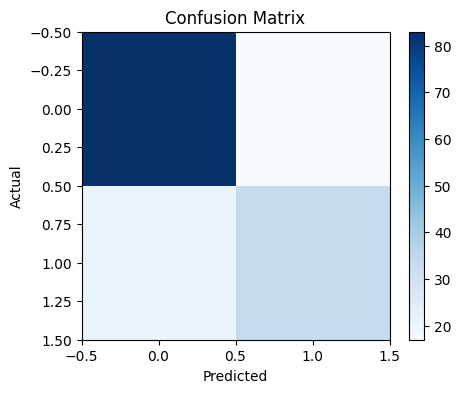

In [18]:
cm = confusion_matrix(y_test, prediction)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.colorbar()

plt.show()

In [19]:
accuracy = accuracy_score(y_test, prediction)

error_rate = 1 - accuracy

precision = precision_score(y_test, prediction)

recall = recall_score(y_test, prediction)

print("Accuracy:", accuracy)

print("Error Rate:", error_rate)

print("Precision:", precision)

print("Recall:", recall)

print("\nClassification Report:")

print(classification_report(y_test, prediction))

Accuracy: 0.7532467532467533
Error Rate: 0.24675324675324672
Precision: 0.66
Recall: 0.6111111111111112

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154

